In [ ]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [ ]:
%%R
cat("hello")

hello

In [ ]:
%%R
# Load Wine Quality dataset
url <- "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

wine <- read.csv(url, sep = ";")

# Select 200 rows instead of 50 to have more data points
set.seed(42)
wine200 <- wine[sample(nrow(wine), 200), ]

# Check the dataset
dim(wine200)

[1] 200  12


In [ ]:
%%R
head(wine200)

     fixed.acidity volatile.acidity citric.acid residual.sugar chlorides
561           12.7             0.60        0.49            2.8     0.075
321            9.8             0.66        0.39            3.2     0.083
1177           6.5             0.88        0.03            5.6     0.079
1098           8.6             0.52        0.38            1.5     0.096
1252           7.5             0.58        0.14            2.2     0.077
1170           7.6             0.50        0.29            2.3     0.086
     free.sulfur.dioxide total.sulfur.dioxide density   pH sulphates alcohol
561                    5                   19 0.99940 3.14      0.57    11.4
321                   21                   59 0.99890 3.37      0.71    11.5
1177                  23                   47 0.99572 3.58      0.50    11.2
1098                   5                   18 0.99666 3.20      0.52     9.4
1252                  27                   60 0.99630 3.28      0.59     9.8
1170                   5   

In [ ]:
%%R
tail(wine200)

     fixed.acidity volatile.acidity citric.acid residual.sugar chlorides
1379           7.2             0.45        0.15            2.0     0.078
984            9.1             0.50        0.30            1.9     0.065
727            8.1             0.72        0.09            2.8     0.084
945            8.3             0.30        0.49            3.8     0.090
1269           6.9             0.41        0.31            2.0     0.079
922            8.4             0.36        0.32            2.2     0.081
     free.sulfur.dioxide total.sulfur.dioxide density   pH sulphates alcohol
1379                  10                   28 0.99609 3.29      0.51     9.9
984                    8                   17 0.99774 3.32      0.71    10.5
727                   18                   49 0.99940 3.43      0.72    11.1
945                   11                   24 0.99498 3.27      0.64    12.1
1269                  21                   51 0.99668 3.47      0.55     9.5
922                   32   

In [ ]:
%%R
dim(wine200)

[1] 50 12


In [ ]:
%%R
str(wine200)

'data.frame':	50 obs. of  12 variables:
 $ fixed.acidity       : num  12.7 9.8 6.5 8.6 7.5 7.6 10.1 6.4 6.1 6.7 ...
 $ volatile.acidity    : num  0.6 0.66 0.88 0.52 0.58 0.5 0.935 0.4 0.58 0.46 ...
 $ citric.acid         : num  0.49 0.39 0.03 0.38 0.14 0.29 0.22 0.23 0.23 0.24 ...
 $ residual.sugar      : num  2.8 3.2 5.6 1.5 2.2 2.3 3.4 1.6 2.5 1.7 ...
 $ chlorides           : num  0.075 0.083 0.079 0.096 0.077 0.086 0.105 0.066 0.044 0.077 ...
 $ free.sulfur.dioxide : num  5 21 23 5 27 5 11 5 16 18 ...
 $ total.sulfur.dioxide: num  19 59 47 18 60 14 86 12 70 34 ...
 $ density             : num  0.999 0.999 0.996 0.997 0.996 ...
 $ pH                  : num  3.14 3.37 3.58 3.2 3.28 3.32 3.43 3.34 3.46 3.39 ...
 $ sulphates           : num  0.57 0.71 0.5 0.52 0.59 0.62 0.64 0.56 0.65 0.6 ...
 $ alcohol             : num  11.4 11.5 11.2 9.4 9.8 11.5 11.3 9.2 12.5 10.6 ...
 $ quality             : int  5 7 4 5 5 6 4 5 6 6 ...


In [ ]:
%%R
colSums(is.na(wine200))

       fixed.acidity     volatile.acidity          citric.acid 
                   0                    0                    0 
      residual.sugar            chlorides  free.sulfur.dioxide 
                   0                    0                    0 
total.sulfur.dioxide              density                   pH 
                   0                    0                    0 
           sulphates              alcohol              quality 
                   0                    0                    0 


In [ ]:
%%R
wine_data <- wine200[, c(
  "alcohol",
  "pH",
  "sulphates",
  "volatile.acidity",
  "citric.acid",
  "quality"
)]

head(wine_data)

     alcohol   pH sulphates volatile.acidity citric.acid quality
561     11.4 3.14      0.57             0.60        0.49       5
321     11.5 3.37      0.71             0.66        0.39       7
1177    11.2 3.58      0.50             0.88        0.03       4
1098     9.4 3.20      0.52             0.52        0.38       5
1252     9.8 3.28      0.59             0.58        0.14       5
1170    11.5 3.32      0.62             0.50        0.29       6


In [ ]:
%%R
wine_data <- na.omit(wine_data)
head(wine_data)

     alcohol   pH sulphates volatile.acidity citric.acid quality
561     11.4 3.14      0.57             0.60        0.49       5
321     11.5 3.37      0.71             0.66        0.39       7
1177    11.2 3.58      0.50             0.88        0.03       4
1098     9.4 3.20      0.52             0.52        0.38       5
1252     9.8 3.28      0.59             0.58        0.14       5
1170    11.5 3.32      0.62             0.50        0.29       6


In [ ]:
%%R
summary(wine_data)

    alcohol             pH          sulphates      volatile.acidity
 Min.   : 9.200   Min.   :3.050   Min.   :0.4500   Min.   :0.2600  
 1st Qu.: 9.525   1st Qu.:3.260   1st Qu.:0.5625   1st Qu.:0.4350  
 Median :10.150   Median :3.315   Median :0.6200   Median :0.5600  
 Mean   :10.565   Mean   :3.348   Mean   :0.6474   Mean   :0.5507  
 3rd Qu.:11.400   3rd Qu.:3.430   3rd Qu.:0.7025   3rd Qu.:0.6600  
 Max.   :12.800   Max.   :4.010   Max.   :1.2600   Max.   :0.9350  
  citric.acid        quality    
 Min.   :0.0000   Min.   :4.00  
 1st Qu.:0.1550   1st Qu.:5.00  
 Median :0.2700   Median :5.00  
 Mean   :0.2706   Mean   :5.48  
 3rd Qu.:0.3700   3rd Qu.:6.00  
 Max.   :0.7600   Max.   :7.00  


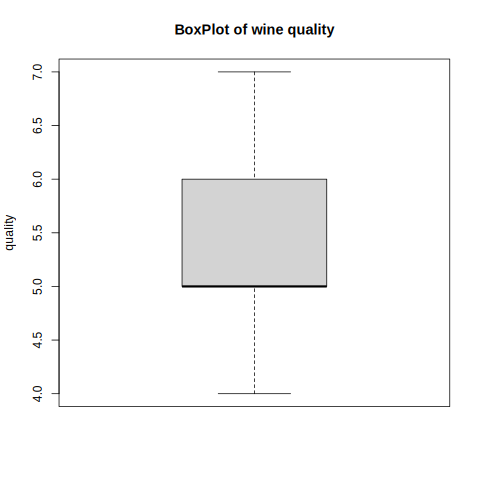

In [ ]:
%%R
boxplot(wine_data$quality,
        main="BoxPlot of wine quality",
        ylab="quality"
)

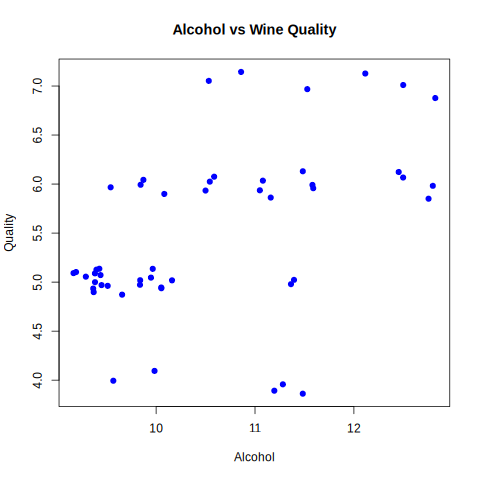

In [ ]:
%%R

plot(
  jitter(wine_data$alcohol, amount = 0.05),
  jitter(wine_data$quality, amount = 0.15),
  main = "Alcohol vs Wine Quality",
  xlab = "Alcohol",
  ylab = "Quality",
  pch = 19,
  col = "blue"
)

In [ ]:
%%R

round(cor(wine_data), 2)

In [ ]:
%%R

linear_model <- lm(
  quality ~ alcohol,
  data = wine_data
)

summary(linear_model)


Call:
lm(formula = quality ~ alcohol, data = wine_data)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.83390 -0.25668 -0.03904  0.46890  1.52568 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.48111    0.99739   1.485 0.144087    
alcohol      0.37850    0.09389   4.031 0.000198 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.7326 on 48 degrees of freedom
Multiple R-squared:  0.2529,	Adjusted R-squared:  0.2374 
F-statistic: 16.25 on 1 and 48 DF,  p-value: 0.0001975



In [ ]:
%%R

new_wine <- data.frame(
  alcohol = 10.5
)

predict(linear_model, new_wine)

       1 
5.455397 


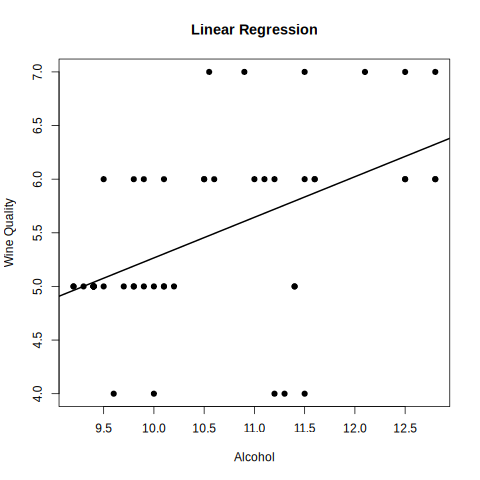

In [ ]:
%%R

plot(
  wine_data$alcohol,
  wine_data$quality,
  main = "Linear Regression",
  xlab = "Alcohol",
  ylab = "Wine Quality",
  pch = 19
)

abline(
  linear_model,
  lwd = 2
)

In [ ]:
%%R

multiple_model <- lm(
  quality ~ alcohol +
    volatile.acidity +
    sulphates +
    pH,
  data = wine_data
)

summary(multiple_model)


Call:
lm(formula = quality ~ alcohol + volatile.acidity + sulphates + 
    pH, data = wine_data)

Residuals:
     Min       1Q   Median       3Q      Max 
-2.06909 -0.26031  0.01391  0.34877  1.40101 

Coefficients:
                 Estimate Std. Error t value Pr(>|t|)   
(Intercept)       -1.3339     1.9442  -0.686  0.49617   
alcohol            0.3224     0.0925   3.485  0.00111 **
volatile.acidity  -2.0235     0.6114  -3.310  0.00185 **
sulphates          1.2105     0.6477   1.869  0.06818 . 
pH                 1.1167     0.6323   1.766  0.08417 . 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.6417 on 45 degrees of freedom
Multiple R-squared:  0.4626,	Adjusted R-squared:  0.4148 
F-statistic: 9.684 on 4 and 45 DF,  p-value: 9.75e-06



In [ ]:
%%R

new_wine_multiple <- data.frame(
  alcohol = 10.5,
  volatile.acidity = 0.50,
  sulphates = 0.65,
  pH = 3.3
)

predict(
  multiple_model,
  new_wine_multiple
)

       1 
5.511625 


In [ ]:
%%R

cat("Simple Linear Regression R²:",
    summary(linear_model)$r.squared, "\n")

cat("Multiple Linear Regression R²:",
    summary(multiple_model)$r.squared, "\n")

Simple Linear Regression R²: 0.2529213 
Multiple Linear Regression R²: 0.4625958 
